### The Flaw of Averages
Imagine a bakery that produces 100 cakes every morning. On average, 100 customers arrive, each willing to pay $\$$10 per cake which costs $\$$6 to produce.

In [1]:
library(ggplot2)

In [2]:
cakes_baked <- 100     # cakes baked every morning
avg_demand <- 100      # average number of customers per day
demand_sd <- 20        # how much demand swings day to day
price <- 10            # selling price per cake
cost <- 6              # cost to bake one cake (unsold cakes are thrown away)
currency <- "$"
set.seed(2026)         # makes results repeatable

Based on the average assumption, the projected daily profit is:
100 cakes sold × $\$$10 − 100 cakes produced × $\$$6 = $400

In [3]:
# Projected daily profit
proj_sold   <- min(avg_demand, cakes_baked)
proj_profit <- price * proj_sold - cost * cakes_baked

The calculation seems straightforward. However, no operating day is truly average.

- On a busy day, 120 customers show up, but the bakery can sell only 100 cakes. The additional demand is lost.
  
- On a slow day, only 80 customers arrive, leaving 20 unsold cakes go to waste.

The underlying problem is asymmetry where busy days offer limited opportunities to increase sales, while slow days generate losses that cannot be recovered. The gains and losses do not cancel each other out.

In [4]:
# Simulation with varying demand
n_days <- 10000 # number of days to simulate
demand <- pmax(0, round(rnorm(n_days, mean = avg_demand, sd = demand_sd)))
sold <- pmin(demand, cakes_baked) # can't sell more than you baked
profit <- price * sold - cost * cakes_baked

real_avg_profit <- mean(profit)
gap_pct <- (proj_profit - real_avg_profit) / proj_profit * 100
sold_out_pct <- mean(demand >= cakes_baked) * 100

cat(sprintf("Plan (using average demand): %s%.0f per day\n", currency, proj_profit))
cat(sprintf("Real average (simulated):    %s%.0f per day\n", currency, real_avg_profit))
cat(sprintf("Plan overstates profit by:   %.0f%%\n", gap_pct))
cat(sprintf("Days the bakery sold out:    %.0f%%\n", sold_out_pct))
cat(sprintf("Days profit beat the plan:   %.0f%%\n", mean(profit > proj_profit) * 100))

Plan (using average demand): $400 per day
Real average (simulated):    $321 per day
Plan overstates profit by:   20%
Days the bakery sold out:    51%
Days profit beat the plan:   0%


A simulation of 10,000 operating days illustrates the impact. The actual average daily profit is $\$$321, 20% below the projected $\$$400.

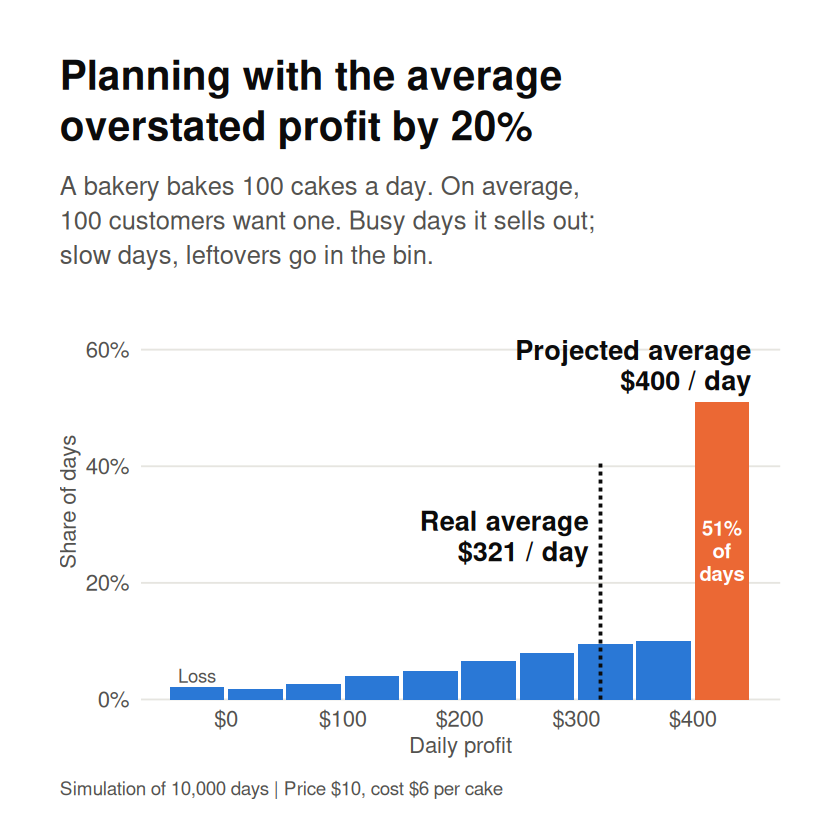

In [7]:
# Chart 
band_width <- 50 # group ordinary days into $50 profit bands
df <- data.frame(profit = profit, sold_out = sold >= cakes_baked)
df$left <- ifelse(df$sold_out, proj_profit,
           ifelse(df$profit < 0, -band_width,
                  floor(df$profit / band_width) * band_width))
bars <- aggregate(list(days = rep(1, nrow(df))),
                  by = list(left = df$left, sold_out = df$sold_out), FUN = sum)
bars$share <- bars$days / n_days * 100
gap <- 4 # small white gap between bars
bars$xmin <- bars$left + gap / 2
bars$xmax <- bars$left + band_width - gap / 2

blue <- "#2a78d6" # ordinary days
orange <- "#eb6834" # sold-out days
ink <- "#0b0b0b"
ink2 <- "#52514e"
top <- max(bars$share)

ggplot(bars) +
geom_rect(aes(xmin = xmin, xmax = xmax, ymin = 0, ymax = share, fill = sold_out)) +
scale_fill_manual(values = c(`FALSE` = blue, `TRUE` = orange), guide = "none") +
# Real average line + label
annotate("segment", x = real_avg_profit, xend = real_avg_profit,
         y = 0, yend = top * 0.8, linetype = "dashed",
         colour = ink, linewidth = 0.8) +
annotate("text", x = real_avg_profit - 10, y = top * 0.55,
         label = sprintf("Real average\n%s%.0f / day", currency, real_avg_profit),
         hjust = 1, size = 5.6, colour = ink, lineheight = 0.95, fontface = "bold") +
# Plan label above the sold-out bar
annotate("text", x = proj_profit + band_width, y = top * 1.04,
         label = sprintf("Projected average\n%s%.0f / day", currency, proj_profit),
         hjust = 1, vjust = 0, size = 5.6, colour = ink, fontface = "bold",
         lineheight = 0.95) +
annotate("text", x = proj_profit + band_width / 2, y = top / 2,
         label = sprintf("%.0f%%\nof\ndays", sold_out_pct),
         size = 4.2, colour = "white", fontface = "bold", lineheight = 0.95) +
annotate("text", x = -band_width / 2, y = top * 0.08,
         label = "Loss", size = 3.8, colour = ink2) +
scale_x_continuous(labels = function(x) paste0(currency, x),
                   breaks = seq(0, proj_profit, by = 100)) +
scale_y_continuous(labels = function(y) paste0(y, "%"),
                   expand = expansion(mult = c(0, 0.28))) +
labs(title = sprintf("Planning with the average\noverstated profit by %.0f%%", gap_pct),
     subtitle = sprintf(paste0("A bakery bakes %d cakes a day. On average,\n",
                               "%d customers want one. Busy days it sells out;\n",
                               "slow days, leftovers go in the bin."),
                        cakes_baked, avg_demand),
     x = "Daily profit",
     y = "Share of days",
     caption = sprintf("Simulation of %s days | Price %s%d, cost %s%d per cake",
                       format(n_days, big.mark = ","), currency, price, currency, cost)) +
theme_minimal(base_size = 15) +
theme(plot.background = element_rect(fill = "white", colour = NA),
      plot.title = element_text(face = "bold", size = 24, colour = ink, lineheight = 1.05),
      plot.subtitle = element_text(size = 15, colour = ink2, lineheight = 1.15,
                                   margin = margin(t = 8, b = 20)),
      plot.caption = element_text(size = 11, colour = ink2, hjust = 0,
                                  margin = margin(t = 14)),
      plot.title.position = "plot",
      plot.caption.position = "plot",
      axis.title = element_text(colour = ink2, size = 13),
      axis.text = element_text(colour = ink2, size = 13),
      panel.grid.major.x = element_blank(),
      panel.grid.minor = element_blank(),
      panel.grid.major.y = element_line(colour = "#e6e5e0", linewidth = 0.4),
      plot.margin = margin(36, 36, 24, 36))

This is the Flaw of Averages where plans based on average assumptions can produce systematically misleading results. The same problem affects inventory management, staffing schedules, project deadlines and business budgets.